# 01NAEX Exercise 08 — Homework — Morovicsova

Solutions to Problems 8.3, 8.9, 8.11, 8.23, 8.24 and 8.27. Run from the repository root or open this notebook in `HW/`; data are read from `../data/`. Effect estimates use the course convention: mean response at sign `+1` minus mean response at sign `-1`. Tests below are exploratory after effect screening.

In [1]:
import itertools
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

from pathlib import Path
DATA = Path("../data") if Path("../data").exists() else Path("data")
URL = str(DATA) + "/"


def multiply(*effects):
    """Product of effects modulo 2 (squared letters cancel): multiply("A", "ABCD") -> "BCD"."""
    letters = reduce(lambda s, e: s ^ set(e), effects, set()) - {"I"}
    return "".join(sorted(letters)) or "I"


def defining_relation(generators):
    """All 2^p - 1 words: the generators and all their products, sorted by length."""
    words = [multiply(*c) for r in range(1, len(generators) + 1)
             for c in itertools.combinations(generators, r)]
    return sorted(words, key=lambda w: (len(w), w))


def aliases(effect, words):
    """Aliases of an effect: the effect times every word of the defining relation."""
    return [multiply(effect, w) for w in words]


def alias_chains(factors, generators, max_order=2):
    """Alias chains of all effects up to max_order (each chain listed once), ignoring longer interactions."""
    words = defining_relation(generators)
    seen, chains = set(), []
    for r in range(1, max_order + 1):
        for c in itertools.combinations(factors, r):
            e = "".join(c)
            chain = [e] + aliases(e, words)
            key = frozenset(chain)
            if key in seen:
                continue
            seen.add(key)
            short = [a for a in chain if len(a) <= max_order]
            chains.append(" = ".join(sorted(short, key=lambda s: (len(s), s))))
    return chains


def fractional_design(basic, added):
    """2^(k-p) design. basic: string of the basic factors, e.g. "ABCD"; added: dict, e.g. {"E": "ABC", "F": "-BCD"}.

    The basic design is a full factorial in standard order (A changes fastest), columns coded -1/+1.
    A leading minus in a generator gives the corresponding alternate fraction.
    """
    d = pd.DataFrame(itertools.product([-1, 1], repeat=len(basic)), columns=list(basic[::-1]))[list(basic)]
    for f, g in added.items():
        sign = -1 if g.startswith("-") else 1
        d[f] = sign * d[list(g.lstrip("-"))].prod(axis=1)
    letters = list(basic) + list(added)
    d.insert(0, "run", d.apply(lambda r: "".join(c.lower() for c in letters if r[c] > 0) or "(1)", axis=1))
    return d


def effect(df, w, y="y"):
    """Effect estimate of the column product w (e.g. "AC"): contrast / (N/2)."""
    s = df[list(w)].prod(axis=1)
    return 2 * (s * df[y]).sum() / len(df)


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names)."""
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: max(m // 2, 2)]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    xl = a + b * qq
    keep = (xl >= x.min() - 0.1 * np.ptp(x)) & (xl <= x.max() + 0.1 * np.ptp(x))
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20, zorder=3)
    ax.plot(xl[keep], qq[keep], color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(-6, 5), textcoords="offset points", ha="right", fontsize=9)
    ax.margins(x=0.12, y=0.12)
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"), fontsize=10)
    ax.grid(alpha=0.3)
    return ax


def alias_matrix(X1, X2):
    """Alias matrix A = (X1'X1)^{-1} X1'X2: E(b1) = beta1 + A beta2 if the effects in X2 are omitted from the model."""
    return np.linalg.solve(X1.T @ X1, X1.T @ X2)


def design_from_runs(runs, factors):
    """Treatment combinations and factor columns coded -1/+1, e.g. design_from_runs(["e", "ab"], "ABCDE")."""
    d = pd.DataFrame({"run": runs})
    for f in factors:
        d[f] = np.where(d["run"].str.contains(f.lower()), 1, -1)
    return d


def wlp(generators, k):
    """Word length pattern (A3, A4, ..., Ak): number of words of each length in the defining relation."""
    lens = [len(w) for w in defining_relation(generators)]
    return [lens.count(L) for L in range(3, k + 1)]

## Problem 8.3 — plasma etch

A half fraction of the $2^3$ design has four treatment combinations, each run twice. Choose $C=AB$, hence $I=ABC$ (resolution III). The four alias chains are $I=ABC$, $A=BC$, $B=AC$, and $C=AB$. Main effects cannot be separated from the corresponding two-factor interactions. The alternate fraction has $C=-AB$ and reverses the signs of those aliases.

In [3]:
p83 = pd.read_csv(URL + "plasma.txt", sep=r"\s+")
long83 = pd.concat([p83.assign(y=p83.R1, rep=1), p83.assign(y=p83.R2, rep=2)], ignore_index=True)
frac83 = long83[long83.A * long83.B * long83.C == 1].copy()
alt83 = long83[long83.A * long83.B * long83.C == -1].copy()
print("Principal runs:", p83.loc[p83.A*p83.B*p83.C == 1, "Run"].tolist())
print("Alternate runs:", p83.loc[p83.A*p83.B*p83.C == -1, "Run"].tolist())
for label, d in [("principal", frac83), ("alternate", alt83), ("full", long83)]:
    print(label, pd.Series({w: effect(d, w) for w in ["A","B","C","AB","AC","BC","ABC"]}).round(2).to_dict())
    print("within-treatment pure-error variance:", round(d.groupby(["A","B","C"]).y.var().mean(), 2))

Principal runs: [2, 3, 5, 8]
Alternate runs: [1, 4, 6, 7]
principal {'A': -103.75, 'B': -146.25, 'C': 281.25, 'AB': 281.25, 'AC': -146.25, 'BC': -103.75, 'ABC': 1557.75}
within-treatment pure-error variance: 2346.38
alternate {'A': -99.5, 'B': 161.0, 'C': 331.0, 'AB': -331.0, 'AC': -161.0, 'BC': 99.5, 'ABC': -1546.5}
within-treatment pure-error variance: 2158.75
full {'A': -101.62, 'B': 7.38, 'C': 306.12, 'AB': -24.88, 'AC': -153.62, 'BC': -2.12, 'ABC': 5.62}
within-treatment pure-error variance: 2252.56


The two fractions give different apparent effects: principal $[B]=-146.25=B+AC$, while alternate $[B]=+161.00=B-AC$. The full design estimates $B=+7.38$ and $AC=-153.62$; $B$ is negligible and $AC$ is active. The full design also finds $A=-101.62$ and $C=+306.12$. Repeated observations provide pure error, but cannot undo aliasing within a fraction. Next run the alternate fraction if only the principal fraction was initially available.

In [5]:
for label, d in [("principal", frac83), ("alternate", alt83), ("full", long83)]:
    formula = "y ~ A+B+C" if label != "full" else "y ~ A*B*C"
    m = smf.ols(formula, data=d).fit()
    print("\n", label, "model:", formula)
    print(anova_lm(m).round(4))
    print("residual MS", round(m.mse_resid, 3))


 principal model: y ~ A+B+C
           df      sum_sq     mean_sq        F  PR(>F)
A         1.0   21528.125   21528.125   9.1751  0.0388
B         1.0   42778.125   42778.125  18.2316  0.0130
C         1.0  158203.125  158203.125  67.4245  0.0012
Residual  4.0    9385.500    2346.375      NaN     NaN
residual MS 2346.375

 alternate model: y ~ A+B+C
           df    sum_sq    mean_sq         F  PR(>F)
A         1.0   19800.5   19800.50    9.1722  0.0388
B         1.0   51842.0   51842.00   24.0148  0.0080
C         1.0  219122.0  219122.00  101.5041  0.0005
Residual  4.0    8635.0    2158.75       NaN     NaN
residual MS 2158.75

 full model: y ~ A*B*C
           df       sum_sq      mean_sq         F  PR(>F)
A         1.0   41310.5625   41310.5625   18.3394  0.0027
B         1.0     217.5625     217.5625    0.0966  0.7639
A:B       1.0    2475.0625    2475.0625    1.0988  0.3252
C         1.0  374850.0625  374850.0625  166.4105  0.0000
A:C       1.0   94402.5625   94402.5625   41.90

For each term in these ANOVAs, $H_0$ is that the corresponding *estimable alias chain* is zero; $H_1$ is that it is nonzero. The printed F statistics and p-values use the replicate error. At 5%, all three apparent main-effect chains in each half fraction are significant, but the full design finds $A$, $C$ and $AC$ significant while $B$ is not ($p=0.764$). Thus the half fraction alone would misleadingly call $B$ active. Treat principal-fraction labels as alias chains, not isolated factor effects.

## Problem 8.9 — chemical product color

The given half fraction has $I=ABCDE$ (resolution V). Each main effect aliases only with a four-factor interaction, and each two-factor interaction aliases with a three-factor interaction: $A=BCDE$, $B=ACDE$, $C=ABDE$, $D=ABCE$, $E=ABCD$; $AB=CDE$, $AC=BDE$, $AD=BCE$, $AE=BCD$, $BC=ADE$, $BD=ACE$, $BE=ACD$, $CD=ABE$, $CE=ABD$, $DE=ABC$. These are the complete nonidentity alias chains.

AB C D E product: [1]
AD   -1.355
B    -1.340
E    -0.827
AC   -0.788
CD   -0.713
CE   -0.240
C    -0.147
DE    0.087
BC    0.168
BD    0.245
BE    0.288
AE    0.302
AB    1.275
A     1.310
D     4.420
dtype: float64
<string>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


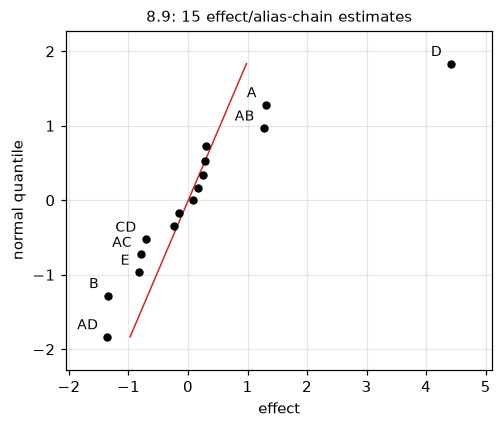

In [8]:
p89 = design_from_runs(["e", "a", "b", "abe", "c", "ace", "bce", "abc", "d", "ade", "bde", "abd", "cde", "acd", "bcd", "abcde"], "ABCDE")
p89["y"] = [-0.63, 2.51, -2.68, 1.66, 2.06, 1.22, -2.09, 1.93, 6.79, 5.47, 3.45, 5.68, 5.22, 4.38, 4.30, 4.05]
words89 = defining_relation(["ABCDE"])
e89 = pd.Series({w: effect(p89,w) for r in (1,2) for t in itertools.combinations("ABCDE",r) for w in ["".join(t)]})
print("AB C D E product:", p89[list("ABCDE")].prod(axis=1).unique())
print(e89.sort_values().round(3))
effect_plot(e89, n_label=8, title="8.9: 15 effect/alias-chain estimates"); plt.show()

The clearest effect is $D$; $A$, $B$, $AB$ and $AD$ are also relatively large and obey heredity. Fit those five terms. $C$ is negligible, so projecting onto $A,B,D,E$ produces a replicated full $2^4$ design: the two values at each projected point differ only in $C$, subject to the original defining relation. Further dropping $E$ gives a replicated full $2^3$ in $A,B,D$ (two observations per combination). The projection supports interpretation of $AB$ and $AD$, while the original fraction still cannot rule out their three-factor aliases.

            df   sum_sq  mean_sq        F  PR(>F)
A          1.0   6.8644   6.8644   7.9382  0.0182
B          1.0   7.1824   7.1824   8.3059  0.0163
D          1.0  78.1456  78.1456  90.3699  0.0000
A:B        1.0   6.5025   6.5025   7.5197  0.0208
A:D        1.0   7.3441   7.3441   8.4929  0.0155
Residual  10.0   8.6473   0.8647      NaN     NaN
coefficients {'Intercept': 2.7075, 'A': 0.655, 'B': -0.67, 'D': 2.21, 'A:B': 0.6375, 'A:D': -0.6775}
R² 0.9246 residual MS 0.8647
<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
projected A,B,D cell means
           mean  count
A  B  D               
-1 -1 -1  0.715      2
       1  6.005      2
    1 -1 -2.385      2
       1  3.875      2
 1 -1 -1  1.865      2
       1  4.925      2
    1 -1  1.795      2
       1  4.865      2


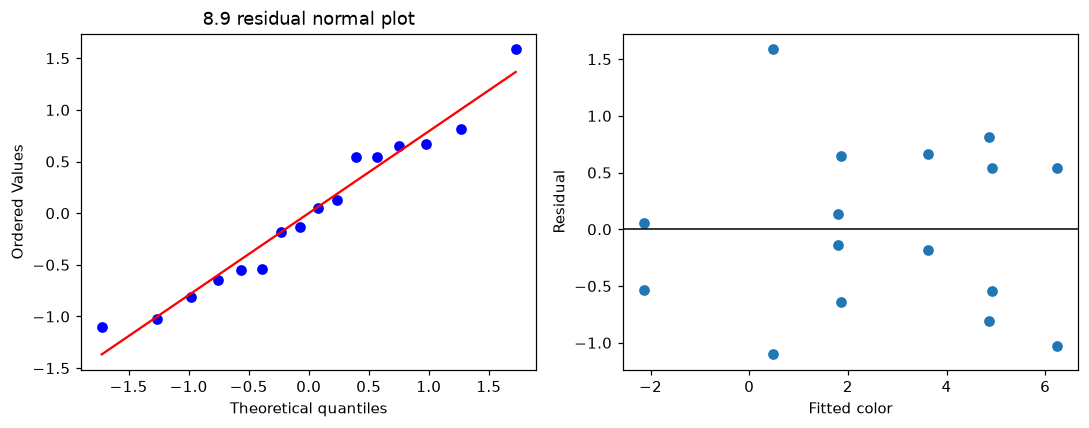

In [10]:
m89 = smf.ols("y ~ A+B+D+A:B+A:D", data=p89).fit()
print(anova_lm(m89).round(4))
print("coefficients", m89.params.round(4).to_dict())
print("R²", round(m89.rsquared,4), "residual MS", round(m89.mse_resid,4))
p89["fit"], p89["resid"] = m89.fittedvalues, m89.resid
fig, ax = plt.subplots(1,2,figsize=(10,4))
stats.probplot(p89.resid, dist="norm", plot=ax[0]); ax[0].set_title("8.9 residual normal plot")
ax[1].scatter(p89.fit,p89.resid); ax[1].axhline(0,color="k",lw=1); ax[1].set(xlabel="Fitted color",ylabel="Residual")
plt.tight_layout();plt.show()
print("projected A,B,D cell means")
print(p89.groupby(["A","B","D"]).y.agg(["mean","count"]).round(3))

For each model term, test $H_0:eta=0$ against $H_1:eta
e0$; the ANOVA gives the F statistic and p-value. At 5%, all five retained terms pass, although this is an exploratory selected model. The residuals are roughly symmetric, and their plot against fitted values shows no obvious trend or change in spread; the $D$ effect dominates. The negative $AD$ effect means raising $A$ has a smaller effect when $D$ is high; $AB$ is positive. For a confirmation, run a few combinations from the alternate $ABCDE=-1$ fraction, especially where model predictions differ most from plausible three-factor aliases.

## Problem 8.11 — yield

The eight run labels satisfy $ACE=+1$ and $BDE=+1$, so the generators are $E=AC$ and $D=BE$ (equivalently the given defining words). Their product is $ABCD$. Complete defining relation: $I=ACE=BDE=ABCD$; resolution III. The seven nonidentity chains are shown below, including all aliases through five factors.

In [13]:
p811 = design_from_runs(["e","ab","ad","bc","cd","ace","bde","abcde"],"ABCDE")
p811["y"] = [23.2,15.5,16.9,16.2,23.8,23.4,16.8,18.1]
print("generator signs", {w:p811[list(w)].prod(axis=1).unique().tolist() for w in ["ACE","BDE","ABCD"]})
words811 = defining_relation(["ACE","BDE"])
print("defining relation", words811)
for chain in alias_chains("ABCDE", ["ACE","BDE"], max_order=5): print(chain)
print("main effects",pd.Series({w:effect(p811,w) for w in "ABCDE"}).round(3))

generator signs {'ACE': [1], 'BDE': [1], 'ABCD': [1]}
defining relation ['ACE', 'BDE', 'ABCD']
A = CE = BCD = ABDE
B = DE = ACD = ABCE
C = AE = ABD = BCDE
D = BE = ABC = ACDE
E = AC = BD = ABCDE
AB = CD = ADE = BCE
AD = BC = ABE = CDE
I = ACE = BDE = ABCD
main effects A   -1.525
B   -5.175
C    2.275
D   -0.675
E    2.275
dtype: float64


The $AB$ and $AD$ chains are not main-effect chains. Assuming their members are negligible lets us pool their two sums of squares as error. This assumption is necessary: with eight unreplicated runs there is no direct pure-error estimate.

           df   sum_sq  mean_sq        F  PR(>F)
A         1.0   4.6512   4.6512   0.9385  0.4349
B         1.0  53.5612  53.5612  10.8068  0.0814
C         1.0  10.3513  10.3513   2.0885  0.2853
D         1.0   0.9112   0.9112   0.1839  0.7098
E         1.0  10.3512  10.3512   2.0885  0.2853
Residual  2.0   9.9125   4.9563      NaN     NaN
error = SS_AB + SS_AD = 9.9125
MSE 4.9563 df 2
<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


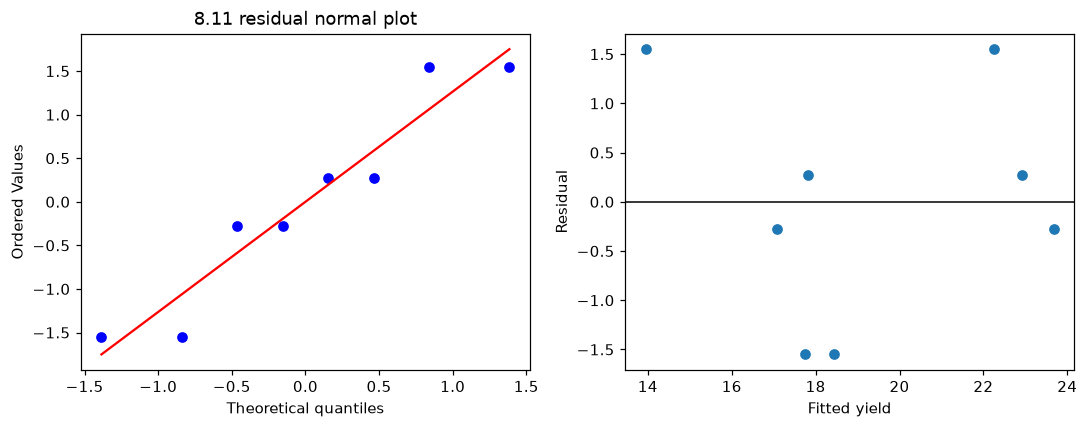

In [15]:
m811 = smf.ols("y ~ A+B+C+D+E",data=p811).fit()
print(anova_lm(m811).round(4))
print("error = SS_AB + SS_AD =",round(8/4*(effect(p811,"AB")**2+effect(p811,"AD")**2),4))
print("MSE",round(m811.mse_resid,4),"df",int(m811.df_resid))
p811["fit"],p811["resid"] = m811.fittedvalues,m811.resid
fig,ax=plt.subplots(1,2,figsize=(10,4))
stats.probplot(p811.resid,dist="norm",plot=ax[0]);ax[0].set_title("8.11 residual normal plot")
ax[1].scatter(p811.fit,p811.resid);ax[1].axhline(0,color="k",lw=1);ax[1].set(xlabel="Fitted yield",ylabel="Residual")
plt.tight_layout();plt.show()

For each main-effect chain, $H_0$ says its estimable contrast is zero and $H_1$ says it is nonzero. The ANOVA prints $F$ and $p$ using only 2 error df. $B/DE$ is largest (estimate $-5.175$), but its $ppprox0.081$ does not cross 5% with this error estimate. Thus the evidence is suggestive, not decisive. $C/AE$ and $E/AC/BD$ are also moderately sized. The eight residuals and 2 error df make diagnostics weak. Add a complementary fraction or replicate selected runs to obtain a real error estimate and resolve the aliases before changing production settings.

## Problem 8.23 — inventory simulation fold-over

Original generators: $D=AB$ and $E=BC$, giving $I=ABD=BCE=ACDE$ (resolution III). Part (b) reverses $D$ only: $D=-AB$, $E=BC$; its defining relation is $I=-ABD=BCE=-ACDE$. Combining with the original retains only $I=BCE$ (16-run resolution III half fraction). Part (c) reverses both $D$ and $E$: $D=-AB$, $E=-BC$; its defining relation is $I=-ABD=-BCE=ACDE$. Combining with the original retains only $I=ACDE$ (16-run resolution IV half fraction).

In [18]:
p823 = design_from_runs(["de","ae","b","abd","cd","ac","bce","abcde"],"ABCDE")
p823["y"] = [95,134,158,190,92,187,155,185]
p823b = design_from_runs(["ade","e","ab","bd","acd","c","abce","bcde"],"ABCDE")
p823b["y"] = [136,93,187,153,139,99,191,150]
p823c = design_from_runs(["abc","ce","bcd","acde","abe","bde","ad","(1)"],"ABCDE")
p823c["y"] = [189,96,154,135,193,152,137,98]
for name,d in [("original",p823),("b",p823b),("c",p823c)]:
    print(name,{w:int(d[list(w)].prod(axis=1).iloc[0]) for w in ["ABD","BCE","ACDE"]})
print("original chains")
for ch in alias_chains("ABCDE",["ABD","BCE"],max_order=5):print(ch)
print("original seven chain estimates",pd.Series({w:effect(p823,w) for w in ["A","B","C","D","E","AC","AE"]}).round(2).to_dict())

original {'ABD': 1, 'BCE': 1, 'ACDE': 1}
b {'ABD': -1, 'BCE': 1, 'ACDE': -1}
c {'ABD': -1, 'BCE': -1, 'ACDE': 1}
original chains
A = BD = CDE = ABCE
B = AD = CE = ABCDE
C = BE = ADE = ABCD
D = AB = ACE = BCDE
E = BC = ACD = ABDE
AC = DE = ABE = BCD
AE = CD = ABC = BDE
I = ABD = BCE = ACDE
original seven chain estimates {'A': 49.0, 'B': 45.0, 'C': 10.5, 'D': -18.0, 'E': -14.5, 'AC': 13.5, 'AE': -14.5}


In [19]:
for name,second,word in [("b",p823b,"BCE"),("c",p823c,"ACDE")]:
    both=pd.concat([p823,second],ignore_index=True)
    print("\ncombined",name,"defining word",word)
    print("alias chains")
    for ch in alias_chains("ABCDE",[word],max_order=2):print(ch)
    print("main effects",pd.Series({w:effect(both,w) for w in "ABCDE"}).round(2).to_dict())
    print("two-factor effects",pd.Series({"".join(t):effect(both,"".join(t)) for t in itertools.combinations("ABCDE",2)}).round(2).to_dict())


combined b defining word BCE
alias chains
A
B = CE
C = BE
D
E = BC
AB
AC
AD
AE
BD
CD
DE
main effects {'A': 44.25, 'B': 49.25, 'C': 6.5, 'D': -8.0, 'E': -8.25}
two-factor effects {'AB': -10.0, 'AC': 7.25, 'AD': -4.25, 'AE': -6.0, 'BC': -8.25, 'BD': 4.75, 'BE': 6.5, 'CD': -8.5, 'CE': 49.25, 'DE': 6.25}

combined c defining word ACDE
alias chains
A
B
C
D
E
AB
AC = DE
AD = CE
AE = CD
BC
BD
BE
main effects {'A': 43.75, 'B': 50.25, 'C': 4.5, 'D': -8.75, 'E': -7.5}
two-factor effects {'AB': -9.25, 'AC': 6.0, 'AD': -5.25, 'AE': -6.5, 'BC': -7.0, 'BD': 5.25, 'BE': 6.0, 'CD': -6.5, 'CE': -5.25, 'DE': 6.0}


Under the assumption that three-factor and higher interactions are negligible, the original large chains suggest $A$ and $B$, but resolution III aliases some main effects with two-factor effects. Adding (b) yields $A=44.25$, $B=49.25$ and $C=6.50$, but $B$ remains aliased with $CE$ because $I=BCE$; the large observed $CE$ pattern is the same column. Adding (c) yields $A=43.75$, $B=50.25$, $C=4.50$, $D=-8.75$, $E=-7.50$; all main effects are clear of two-factor interactions under resolution IV, so this is the better follow-up when the goal is screening main effects. In (c), two-factor pairs remain aliased (for example $AC=DE$). The cost response increases strongly when $A$ or $B$ is high, suggesting low settings for both, pending confirmation. There are no replication-based p-values for these deterministic simulation outputs; further simulation replications would permit uncertainty estimates.

## Problem 8.24 — half fraction in two blocks

Choose $E=ABCD$, so $I=ABCDE$ and the 16-run fraction has resolution V. Use $AB$ as the block generator: eight runs have $AB=+1$ and eight have $AB=-1$. The complete *treatment* defining relation remains $I=ABCDE$. Its $AB$ treatment chain is $AB=CDE$. Since the block column is exactly $AB$, the block contrast is confounded with $AB$ and $CDE$. All five main effects remain unconfounded with blocks, but one two-factor interaction is lost. This is unavoidable for a two-block, resolution V half fraction: a nonconstant block sign column represents one of the 15 treatment chains; any such choice aliases with a main effect or a two-factor effect (and possibly a higher-order effect).

In [22]:
d824=fractional_design("ABCD",{"E":"ABCD"})
d824["Block"] = np.where(d824.A*d824.B==1,1,2)
print(d824.to_string(index=False))
print("block sizes",d824.groupby("Block").size().to_dict())
print("treatment relation",defining_relation(["ABCDE"]))
print("block confounded with",["AB"]+aliases("AB",defining_relation(["ABCDE"])))

  run  A  B  C  D  E  Block
    e -1 -1 -1 -1  1      1
    a  1 -1 -1 -1 -1      2
    b -1  1 -1 -1 -1      2
  abe  1  1 -1 -1  1      1
    c -1 -1  1 -1 -1      1
  ace  1 -1  1 -1  1      2
  bce -1  1  1 -1  1      2
  abc  1  1  1 -1 -1      1
    d -1 -1 -1  1 -1      1
  ade  1 -1 -1  1  1      2
  bde -1  1 -1  1  1      2
  abd  1  1 -1  1 -1      1
  cde -1 -1  1  1  1      1
  acd  1 -1  1  1 -1      2
  bcd -1  1  1  1 -1      2
abcde  1  1  1  1  1      1
block sizes {1: 8, 2: 8}
treatment relation ['ABCDE']
block confounded with ['AB', 'CDE']


A physical block could be a furnace load or day; randomize run order within each block. If $AB$ may be scientifically important, choose another two-factor chain to sacrifice, or add another fraction/replicate to recover information.

## Problem 8.27 — carbon anodes

The eight labels satisfy $I=ABD=ACE=BCF$. Products of these generators give the complete relation $I=ABD=ACE=BCF=DEF=ABEF=ACDF=BCDE$. The shortest word has length 3, so this is a $2^{6-3}_{III}$ design. Each of the seven estimable nonidentity chains contains several effects; the short members are printed below. The three values at each point are replicates. Analyze their mean for location and their range for dispersion.

defining relation ['ABD', 'ACE', 'BCF', 'DEF', 'ABEF', 'ACDF', 'BCDE']
A = BD = CE = BEF = CDF = ABCF = ADEF = ABCDE
B = AD = CF = AEF = CDE = ABCE = BDEF = ABCDF
C = AE = BF = ADF = BDE = ABCD = CDEF = ABCEF
D = AB = EF = ACF = BCE = ACDE = BCDF = ABDEF
E = AC = DF = ABF = BCD = ABDE = BCEF = ACDEF
F = BC = DE = ABE = ACD = ABDF = ACEF = BCDEF
AF = BE = CD = ABC = ADE = BDF = CEF = ABCDEF
I = ABD = ACE = BCF = DEF = ABEF = ACDF = BCDE
   run    mean  range
   abd  915.33    158
abcdef 1236.00    481
    be 1102.67    327
    af 1393.00    377
   def 1129.67    407
    cd  763.67    116
   ace 1295.33     84
   bcf 1292.33     72
mean effects {'A': 137.83, 'B': -8.83, 'C': 11.67, 'D': -259.67, 'E': 99.83, 'F': 243.5, 'AF': -34.33}
<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
range effects {'A': 44.5, 'B': 13.5, 'C': -129.0, 'D': 75.5, 'E': 144.0, 'F': 163.0, 'AF': 145.0}
<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus can

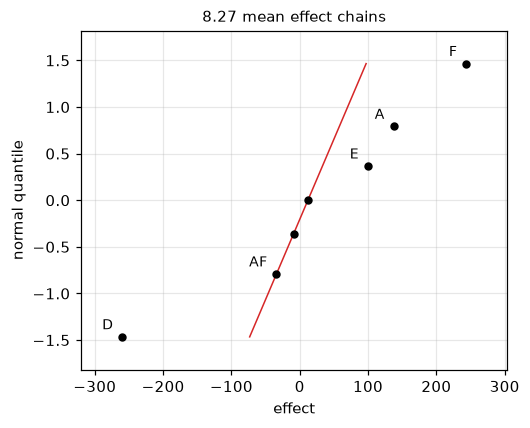

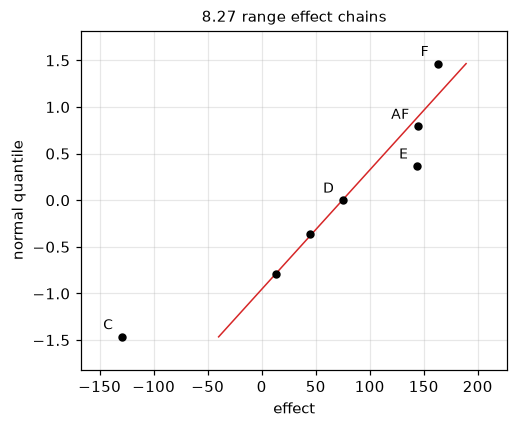

In [25]:
p827=design_from_runs(["abd","abcdef","be","af","def","cd","ace","bcf"],"ABCDEF")
p827["w1"]=[984,1275,1217,1474,1320,765,1338,1325]
p827["w2"]=[826,976,1201,1164,1156,705,1254,1299]
p827["w3"]=[936,1457,890,1541,913,821,1294,1253]
p827["mean"]=p827[["w1","w2","w3"]].mean(axis=1)
p827["range"]=p827[["w1","w2","w3"]].max(axis=1)-p827[["w1","w2","w3"]].min(axis=1)
words827=defining_relation(["ABD","ACE","BCF"])
print("defining relation",words827)
for ch in alias_chains("ABCDEF",["ABD","ACE","BCF"],max_order=6):print(ch)
print(p827[["run","mean","range"]].round(2).to_string(index=False))
for y in ["mean","range"]:
    e=pd.Series({w:effect(p827.rename(columns={y:"y"}),w) for w in ["A","B","C","D","E","F","AF"]})
    print(y,"effects",e.round(2).to_dict())
    effect_plot(e,title="8.27 "+y+" effect chains");plt.show()

For average sticking, the largest chains are $D=-259.67$, $F=+243.50$, then $A=+137.83$ and $E=+99.83$ g. For ranges, $F=+163$, the $AF/BE/CD$ chain $=+145$, $E=+144$, and $C=-129$ g stand out, although eight points provide little separation among them. These are *chains*, not proven isolated main effects: e.g. $D=AB=EF$, $F=BC=DE$, $A=BD=CE$, $E=AC=DF$, and $C=AE=BF$ among low-order terms. The large $AF/BE/CD$ range chain cannot be attributed to one of its members. The direct observed minimum mean is run `cd` (both $C,D$ high and others low): about 763.67 g; its range is 116 g. The $D+$, $F-$ direction is promising for lowering average sticking; delay at $F+$ appears to raise both mean and spread. Recommend follow-up runs, including the opposite fractions or targeted combinations, with replicated measurements before prescribing settings. A normal plot of just seven chains is a screening aid, not a reliable significance test. No formal tests are claimed because assigning pooled error in this saturated design would require additional sparsity assumptions.